### Generate box plots to identify outliers by computing quartiles, IQR, and fences manually, and visualize them using raw Matplotlib drawing functions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
data = sorted(df["age"].dropna().tolist())

In [4]:
q1 = data[len(data)//4]
q2 = data[len(data)//2]
q3 = data[3*len(data)//4]

print(q1, q2, q3)

47 55 61


In [5]:
iqr = q3 - q1

print("IQR:", iqr)

IQR: 14


In [6]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print("Lower:", lower)
print("Upper:", upper)

Lower: 26.0
Upper: 82.0


In [7]:
outliers = [x for x in data if x < lower or x > upper]

print("Outliers:", outliers)

Outliers: []


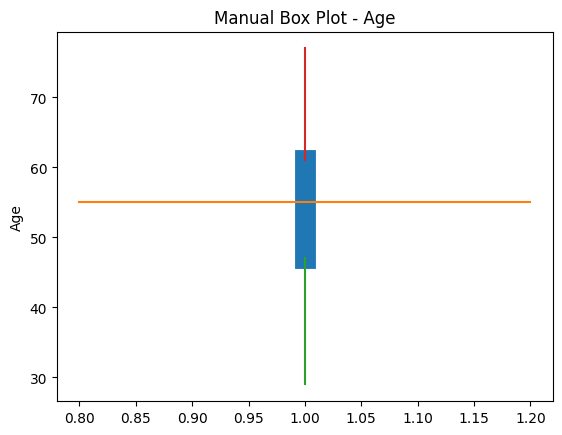

In [8]:
low = min(x for x in data if x >= lower)
high = max(x for x in data if x <= upper)

plt.plot([1, 1], [q1, q3], linewidth=15)
plt.plot([0.8, 1.2], [q2, q2])
plt.plot([1, 1], [low, q1])
plt.plot([1, 1], [q3, high])
plt.scatter([1]*len(outliers), outliers)

plt.title("Manual Box Plot - Age")
plt.ylabel("Age")
plt.show()